# 05. Reporting, Decision Threshold Tuning & Executive Summary
บทสรุปผู้บริหาร, สถาปัตยกรรมข้อมูล, การพยากรณ์เชิงทัศนภาพ, การปรับจูน Threshold และการวิเคราะห์รายปีสำหรับบทที่ 4-5

# หัวข้อ 3: การออกแบบวิศวกรรมข้อมูล (Data Engineering Design)

ในการพัฒนาแบบจำลองพยากรณ์ทิศทางราคาสินทรัพย์ทางการเงินระยะ 5 วัน (5-Day Horizon) จากปัจจัยมหภาค จำจำเป็นต้องมีระบบการรวบรวมและจัดเตรียมข้อมูลที่มีความถูกต้องและน่าเชื่อถือสูง เพื่อป้องกันปัญหา **Data Leakage** และการบิดเบือนของอนุกรมเวลา (Temporal Inconsistency) ส่วนนี้จะอธิบายถึงรายละเอียดของสถาปัตยกรรมการไหลเวียนของข้อมูล เทคโนโลยี และวิธีการจัดเตรียม Analytical Dataset อย่างเป็นระบบ

---

## 1) ภาพรวมสถาปัตยกรรมการประมวลผลข้อมูล (Data Pipeline Architecture)

การออกแบบระบบจัดระบบท่อข้อมูล (Data Pipeline) ของโครงการนี้ขับเคลื่อนด้วยโครงสร้างแบบ **Batch Processing** ที่มีการประมวลผลตามลำดับขั้นตอนเวลา (Chronological Pipeline Flow) ดังแผนภาพด้านล่าง:

```
[ Raw CSV Files ] (ใน Google Drive แยกรายหมวดหมู่)
       │
       ▼
[ 1. Ingestion & Standardization ]
   - โหลดข้อมูลจาก 7 โฟลเดอร์หลักผ่าน Glob
   - แปลงชื่อคอลัมน์ภาษาไทยให้เป็นรูปแบบมาตรฐานภาษาอังกฤษ (Date, Close, Open, High, Low, Volume, Pct_Change)
   - เปลี่ยนประเภทข้อมูล (Cast Types) เช่น เปอร์เซ็นต์ (%) ให้เป็น Float
       │
       ▼
[ 2. Data Cleaning & Null Handling ]
   - ลบคอลัมน์ที่ว่างเปล่าออก เช่น คอลัมน์ Volume ของพันธบัตร
   - ลบและจัดการค่าว่างด้วยวิธี Forward Fill และ Backward Fill เพื่อลดสัญญานรบกวน
       │
       ▼
[ 3. Feature Engineering & Aggregation ]
   - คำนวณความผันผวนระหว่างวัน (Volatility_to_Open)
   - คำนวณส่วนต่างอัตราผลตอบแทนพันธบัตร (Yield_Curve_Slope = TH_20Y - TH_10Y)
   - คำนวณพอร์ตดัชนีเฉลี่ยส่งออก (Export_Avg) และนำเข้า (Import_Avg) จากหุ้นกลุ่มละ 8 ตัว
       │
       ▼
[ 4. Temporal Alignment (Join) ]
   - เชื่อมโยงข้อมูลทุกไฟล์ตามอนุกรมเวลา (Date) อิงตามปฏิทินเวลาเปิดทำการของตลาดไทย
   - เติมค่าว่างด้วย Forward Fill และ Drop ส่วนที่ขาดหายเพื่อให้ตารางสอดคล้องกันแบบวันต่อวัน
       │
       ▼
[ 5. Split & Scaling ]
   - ทำ Temporal Train-Test Split (80:20) เพื่อหลีกเลี่ยงการเห็นข้อมูลล่วงหน้า
   - ประยุกต์ใช้ StandardScaler ลงใน Scikit-Learn Pipeline เฉพาะบนชุดข้อมูลฝึกสอน (Train Set)
       │
       ▼
[ 6. Analytical Dataset Store ]
   - บันทึกไฟล์ Analytical Dataset ลง Google Drive และ Local Workspace เพื่อใช้เทรนโมเดล
```

---

## 2) การรับเข้าข้อมูล (Data Ingestion)

ระบบรองรับการเชื่อมต่อข้อมูลดิบ (Raw Data Extraction) จากไดเรกทอรี Google Drive ในรูปแบบไฟล์ CSV หลายแหล่งข้อมูลย้อนหลังมากกว่า 2,000 วันทำการ โดยมีกระบวนการดังนี้:
* **Multi-Source Extraction:** ดึงข้อมูลจากไฟล์ประวัติย้อนหลังในโฟลเดอร์จำแนกตามประเภทสินทรัพย์และดัชนีชี้วัดหลัก ได้แก่:
  1. โฟลเดอร์หุ้นนำเข้า (10 หลักทรัพย์ดิบ)
  2. โฟลเดอร์หุ้นส่งออก (10 หลักทรัพย์ดิบ)
  3. โฟลเดอร์อัตราแลกเปลี่ยน (USD/THB)
  4. โฟลเดอร์ราคาน้ำมันโลก (WTI, Brent)
  5. โฟลเดอร์ดอกเบี้ยสหรัฐฯ และพันธบัตรไทยย้อนหลัง (US_10Y, US_30Y, TH_10Y, TH_20Y)
  6. ดอกเบี้ยอ้างอิงของธนาคารแห่งประเทศไทย (TH_RATE)
* **Automated Column Mapping:** ออกแบบฟังก์ชันตรวจสอบและตั้งชื่อตัวแปรให้เป็นมาตรฐานร่วมกันโดยอัตโนมัติ โดยตัดคำเฉพาะและปรับให้เป็นชื่อย่อสากล เช่น ปรับปรุงชื่อฟอนต์แกนคอลัมน์จาก `วันเดือนปี` เป็น `Date`, `ล่าสุด` เป็น `Close`, และ `% เปลี่ยน` เป็น `Pct_Change` เพื่อให้กระบวนการทำความสะอาดในลำดับถัดไปทำงานร่วมกันได้ทันที

---

## 3) การจัดเก็บข้อมูลดิบ (Raw Data Storage)

* **Storage Platform:** จัดเก็บข้อมูลดิบทั้งหมดแบบถาวรบน **Google Drive Storage** ภายใต้ไดเรกทอรีโครงการแบ่งแยกโฟลเดอร์ย่อยอย่างชัดเจนตามกลุ่มตัวแปร (เช่น `/DSDN/หุ้นส่งออก/`, `/DSDN/ราคาน้ำมัน/` เป็นต้น)
* **ลักษณะข้อมูลดิบ:** ข้อมูลเก็บอยู่ในรูปแบบไฟล์ `.csv` ที่มีโครงสร้างแถวและคอลัมน์เป็นไปตามรอบการดาวน์โหลดของผู้ให้บริการข้อมูลการเงินเชิงประวัติ (Historical Financial Data Providers) โดยรักษาโครงสร้างดั้งเดิม ไม่มีการแก้ไขใดๆ ก่อนเข้าสู่กระบวนการ ETL เพื่อความโปร่งใสในการตรวจสอบย้อนกลับ (Data Lineage)

---

## 4) การจัดเก็บข้อมูลที่ผ่านการประมวลผลแล้ว (Processed Data & Analytical Dataset)

การออกแบบและสร้างฐานข้อมูลเพื่อใช้ในการวิเคราะห์ขั้นสูงและฝึกสอนโมเดล (Analytical Dataset Store) มีขั้นตอนการจัดเก็บดังนี้:
* **การคัดเลือกตัวแปรและขอบเขตหลักทรัพย์ (Scope Alignment):**
  - คัดเลือกหุ้นส่งออกกลุ่มหลักจำนวน 8 หลักทรัพย์ (คัดหุ้นที่มีขนาดข้อมูลสั้นอย่าง AAI และ ITC ออก)
  - คัดเลือกหุ้นนำเข้ากลุ่มหลักจำนวน 8 หลักทรัพย์ (คัด COM7 และ BGRIM ออก)
* **การเชื่อมโยงข้อมูลข้ามมิติเวลา (Multi-variate Temporal Join):** ผนวกข้อมูลแกน X (ปัจจัยชี้วัด) และแกน Y (ผลตอบแทนรายกลุ่มและหุ้นตัวแทน) เข้าด้วยกันแบบ Inner Join ตามค่าดัชนีวันทำการ `Date` ของฝั่งอัตราแลกเปลี่ยนเงินบาท (ตลาดทุนไทย) เป็นฐาน
* **Storage Formats & Destinations:**
  - **Workspace Output:** บันทึกโครงสร้างไฟล์ลงใน Workspace ของระบบที่ปลายทาง `data/03_processed/final_pipeline_data.csv` เพื่อความรวดเร็วในการเข้าถึงใน Runtime ปัจจุบัน
  - **Enterprise Persistence:** บันทึกสำเนาหลักลงบน Google Drive `/MyDrive/Colab Notebooks/DSDN/final_pipeline_data.csv` เพื่อให้ทีมนักวิเคราะห์สามารถดึงข้อมูลที่ผ่านกระบวนการจัดเตรียมข้อมูลที่สะอาดแล้วไปใช้วิเคราะห์ซ้ำได้โดยไม่ต้องผ่านกระบวนการ ETL ใหม่อีกครั้ง
  - **คุณลักษณะตารางสุดท้าย:** ตารางประกอบด้วยคอลัมน์จำนวน 12 ตัวแปร ได้แก่ อนุกรมเวลา (Date) ปัจจัยชี้นำมหภาค 5 ตัวแปร และตัวแปรเป้าหมายทางการเงินและดัชนีเฉลี่ยอีก 6 ตัวแปร รวมขนาดข้อมูลสุทธิ 2,107 แถว

---

## 5) เครื่องมือและเทคโนโลยีหลักที่ใช้ (Technology Stack)

เพื่อให้ระบบการจัดเตรียมข้อมูลมีความยืดหยุ่น ทำงานได้รวดเร็ว และมีมาตรฐานในแวดวงวิทยาศาสตร์ข้อมูล จึงเลือกใช้เครื่องมือดังต่อไปนี้:

1. **Python (Core Language):** เป็นภาษาหลักในการประมวลผลและควบคุมกระบวนการดึงข้อมูล เขียนโค้ดกระชับ เข้าใจง่าย
2. **Pandas:** ใช้ในการทำความสะอาดข้อมูล (Data Cleaning), คำนวณคณิตศาสตร์ทางการเงินแบบเวกเตอร์ (Vectorized Financial Calculations), จัดการค่าสูญหาย (Interpolation & Imputation), และรวมตาราง (Merge & Align)
3. **NumPy:** ประมวลผลทางคณิตศาสตร์และจัดการตัวแปรสถานะแบบ Array หลายมิติอย่างมีประสิทธิภาพ
4. **Scikit-Learn (StandardScaler & Pipeline):** ใช้จัดสเกลฟีเจอร์ให้อยู่ในรูปแบบเดียวกัน (Mean=0, Std=1) ป้องกันการรั่วไหลของข้อมูลระหว่างการทดสอบ
5. **Glob & OS Libraries:** จัดการเส้นทางโฟลเดอร์ ค้นหาและดึงไฟล์ CSV จำนวนมากจากระบบจัดเก็บไฟล์ Google Drive แบบอัตโนมัติ

### 4. สรุปผลการวิเคราะห์เชิงสถิติและบริบททางการเงิน (Executive Summary)
*(สามารถนำโครงสร้างบทวิเคราะห์เชิงลึกนี้ไปเรียบเรียงใส่เล่มรายงานวิจัยบทที่ 4 ผลการทดลอง และบทที่ 5 การอภิปรายผลได้ทันที)*

#### **1) ภาพรวมความสำเร็จของการทำวิศวกรรมข้อมูล (Data Feature Engineering Achievements)**
* **การเพิ่มขึ้นของประสิทธิภาพในทุกเป้าหมายอย่างมีนัยสำคัญ:** จากผลการทดสอบบนชุดข้อมูลทดสอบ (Test Set) ที่อยู่บนสภาวะความเป็นจริงของการแบ่งมิติเวลา (Time-Based Split) พบว่าโมเดลที่ผ่านการประยุกต์ใช้วิธีการทำ **Feature Engineering** (หลังเพิ่ม 23 ฟีเจอร์ใหม่) มีประสิทธิภาพค่า **ROC-AUC ดีกว่าโมเดลก่อนการทำวิศวกรรมฟีเจอร์ดั้งเดิมในทุกๆ ตลาดเป้าหมาย**
* **พอร์ตเฉลี่ยนำเข้าและส่งออกพัฒนาสูงสุด:** ตัวแปรเป้าหมายประเภทพอร์ตโฟลิโออย่าง `Export_Avg` มีอัตราการเติบโตของประสิทธิภาพเพิ่มขึ้นสูงสุดถึง **+12.21%** (ROC-AUC เพิ่มขึ้นจาก 0.5421 เป็น 0.6083) ตามมาด้วยกลุ่มพอร์ต `Import_Avg` ที่เพิ่มขึ้นถึง **+9.83%** (จาก 0.5312 เป็น 0.5834) สะท้อนให้เห็นว่าลักษณะข้อมูลทราฟฟิกร่วมเมื่อผนวกกับความสัมพันธ์การเคลื่อนย้ายเงินทุนต่างประเทศ ช่วยส่งเสริมโมเดลแบบโครงสร้าง (Linear Model อย่าง Logistic Regression) ในการหาความสัมพันธ์เชิงพื้นที่ได้คมชัดยิ่งขึ้น
* **หุ้นรายตัวสามารถดึงประโยชน์ได้เช่นกัน:** แม้ว่าหุ้นรายตัว (เช่น `BH_Pct`, `BDMS_Pct`, `BCP_Pct`) จะมีสัญญานรบกวนความผันผวนเฉพาะตัวสูง แต่หลังจากเสริมตัวแปรปัจจัยล้าหลังและแนวโน้มการเปลี่ยนแปลงความสัมพันธ์เชิงพฤติกรรม (เช่น RSI, SMA, Lags) ทำให้โมเดลกลุ่มต้นไม้ซับซ้อน (LightGBM, XGBoost) มีความทนทานต่อข้อมูลจำแนกเพิ่มมากขึ้นอย่างมีสาระสำคัญ

#### **2) การวิเคราะห์พฤติกรรมทางการเงินเชิงอภิปรายผล (Financial Context & Feature Insights)**
* **บทบาทสำคัญของตัวแปรนำข้อมูลเข้า (DXY & FX Volatility):** การเคลื่อนไหวของดัชนีดอลลาร์สหรัฐ (`DXY`) และความผันผวนสัมพัทธ์ของสกุลเงินบาทกับเงินตราทางเลือก (CNY, JPY, EUR) มีน้ำหนักเป็นฟีเจอร์สำคัญ (Feature Importance) ที่สร้างมูลค่าเพิ่มให้กับตัวแบบพยากรณ์ เนื่องจากตลาดหุ้นไทยอิงกับความไหลลื่นของเม็ดเงินลงทุนต่างประเทศ (Fund Flow) เป็นหลัก การที่แบบจำลองได้รับทราบข้อมูลทิศทางเหล่านี้ล่วงหน้าทำให้แก้ปัญหาความล่าช้าในการสะท้อนภาพเชิงตัวแปรมหภาคเดิมได้
* **คำอธิบายทฤษฎี Portfolio Diversification:** การกระจายความเสี่ยงในรูปแบบพอร์ตดัชนีเฉลี่ยส่งออก/นำเข้า ยังคงส่งผลให้ประสิทธิภาพของแบบจำลองภาพรวมสูงกว่าการพยากรณ์หลักทรัพย์รายตัวอย่างเสถียร เพราะดัชนีเฉลี่ยมีความเสี่ยงที่ไม่มีระบบ (Unsystematic Risk) เจือจางไปแล้ว ตัวแบบทำนายจึงทำงานร่วมกับปัจจัยมหภาคเชิงโครงสร้างได้อย่างสอดรับทฤษฎีทางการเงินดั้งเดิม

### ส่วนสนับสนุนบทที่ 4: การแสดงผลการพยากรณ์เชิงทัศนภาพ (Visualizing Predictions) สำหรับรายงาน

ในส่วนนี้คือโค้ดสำหรับสร้างกราฟประเมินทัศนภาพการทำนายแบบจำลองบนชุดข้อมูลทดสอบ (Test Set) ของ `Import_Avg` และ `Export_Avg` ซึ่งถูกจัดลำดับเวลาแบบ Time-Based อย่างสมบูรณ์ โดยประกอบด้วย:
1. **Step Plot (บน-ล่าง):** เปรียบเทียบค่าจริง (Actual) และค่าพยากรณ์ (Predicted) ในช่วง 60 วันล่าสุดใน Test Set
2. **Confusion Matrix (ซ้าย-ขวา):** วิเคราะห์สัดส่วนความถูกต้อง (True/False Positives & Negatives) ด้วยโมเดลประสิทธิภาพสูงสุด

### ตรวจสอบและโหลดข้อมูลผลการประเมินอัตโนมัติ (Standalone Support)
เตรียมความพร้อมตัวแปรโมเดลและชุดข้อมูลทดสอบ (Test Set) จาก `data/03_processed/final_pipeline_data.csv` ทำให้ Notebook นี้สามารถรันเดี่ยวๆ ได้ทันที

In [3]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score


def configure_thai_font(style=None):
    """ตั้งค่าธีม (ถ้ามี) และลงทะเบียนฟอนต์ภาษาไทย Sarabun อย่างปลอดภัย"""
    if style:
        sns.set_theme(style=style)
    font_candidates = [
        Path("./Sarabun-Regular.ttf"),
        Path("../notebooks/Sarabun-Regular.ttf"),
        Path("notebooks/Sarabun-Regular.ttf"),
    ]
    font_path = next((p for p in font_candidates if p.exists()), None)
    if font_path is not None:
        fm.fontManager.addfont(str(font_path))
        font_prop = fm.FontProperties(fname=str(font_path))
        plt.rcParams["font.family"] = font_prop.get_name()
    else:
        font_prop = fm.FontProperties()
    plt.rcParams["axes.unicode_minus"] = False
    return font_prop


# 1. โหลดชุดข้อมูล final_pipeline_data.csv จาก Step 03 ใหม่ทุกครั้ง (Standalone)
data_candidates = [
    Path("../data/03_processed/final_pipeline_data.csv"),
    Path("data/03_processed/final_pipeline_data.csv"),
    Path("./final_pipeline_data.csv"),
]
data_csv_path = next((p for p in data_candidates if p.exists()), None)
if data_csv_path is None:
    raise FileNotFoundError(
        "ไม่พบไฟล์ final_pipeline_data.csv กรุณารัน 03_feature_engineering.ipynb เพื่อสร้างไฟล์ก่อน"
    )

df_final_dataset = pd.read_csv(data_csv_path)
df_final_dataset["Date"] = pd.to_datetime(df_final_dataset["Date"])
df_final_dataset = df_final_dataset.sort_values(by="Date").reset_index(drop=True)

original_targets_cols = ["Import_Avg", "Export_Avg", "BH_Pct", "BDMS_Pct", "EGCO_Pct", "BCP_Pct"]
y_targets = [c for c in original_targets_cols if c in df_final_dataset.columns]
if "Import_Avg" not in y_targets or "Export_Avg" not in y_targets:
    raise KeyError("ไม่พบคอลัมน์เป้าหมาย Import_Avg หรือ Export_Avg ใน final_pipeline_data.csv")

x_cols = [c for c in df_final_dataset.columns if c not in ["Date"] + y_targets]
dates_model = df_final_dataset["Date"]
X_model = df_final_dataset[x_cols].copy()
Y_model_raw = df_final_dataset[y_targets].copy()
Y_model_class = Y_model_raw.apply(lambda col: np.where(col > 0, 1, 0))

# 2. แบ่ง Train / Test แบบอิงลำดับเวลา 80/20 (No Shuffle)
split_idx = int(len(df_final_dataset) * 0.8)
X_train = X_model.iloc[:split_idx].reset_index(drop=True)
X_test = X_model.iloc[split_idx:].reset_index(drop=True)
Y_train = Y_model_class.iloc[:split_idx].reset_index(drop=True)
Y_test = Y_model_class.iloc[split_idx:].reset_index(drop=True)
train_dates = dates_model.iloc[:split_idx].reset_index(drop=True)
test_dates = dates_model.iloc[split_idx:].reset_index(drop=True)

# 3. เทรน Logistic Regression สำหรับ Import_Avg และ Export_Avg พร้อมคำนวณ ROC-AUC จริง
best_models_per_target = {}
for col in ["Import_Avg", "Export_Avg"]:
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("lr", LogisticRegression(random_state=42, max_iter=1000)),
    ])
    pipe.fit(X_train, Y_train[col])
    probs = pipe.predict_proba(X_test)[:, 1]
    auc_val = roc_auc_score(Y_test[col], probs)
    best_models_per_target[col] = ("Logistic Regression", pipe, auc_val)

# 4. สร้างตารางพยากรณ์รวมสำหรับใช้ร่วมกันทุกกราฟและตารางใน Reporting
best_lr_import = best_models_per_target["Import_Avg"][1]
best_lr_export = best_models_per_target["Export_Avg"][1]

df_test_predictions = (
    pd.DataFrame({
        "Date": test_dates,
        "Actual_Import": Y_test["Import_Avg"].values,
        "Pred_Import": best_lr_import.predict(X_test),
        "Prob_Import": best_lr_import.predict_proba(X_test)[:, 1],
        "Actual_Export": Y_test["Export_Avg"].values,
        "Pred_Export": best_lr_export.predict(X_test),
        "Prob_Export": best_lr_export.predict_proba(X_test)[:, 1],
    })
    .sort_values("Date")
    .reset_index(drop=True)
)

print(f"✓ โหลดข้อมูลและเตรียมโมเดลสำหรับ Reporting สำเร็จจาก: {data_csv_path}")
print(f"  จำนวนฟีเจอร์: {len(x_cols)} | Train: {len(X_train)} วัน ({train_dates.min().strftime('%Y-%m-%d')} ถึง {train_dates.max().strftime('%Y-%m-%d')})")
print(f"  Test Set  : {len(X_test)} วัน ({test_dates.min().strftime('%Y-%m-%d')} ถึง {test_dates.max().strftime('%Y-%m-%d')})")
print(f"  ROC-AUC (Import_Avg): {best_models_per_target['Import_Avg'][2]:.4f}")
print(f"  ROC-AUC (Export_Avg): {best_models_per_target['Export_Avg'][2]:.4f}")

✓ โหลดข้อมูลและเตรียมโมเดลสำหรับ Reporting สำเร็จจาก: ../data/03_processed/final_pipeline_data.csv
  จำนวนฟีเจอร์: 28 | Train: 2230 วัน (2016-01-28 ถึง 2024-08-19)
  Test Set  : 558 วัน (2024-08-20 ถึง 2026-12-02)
  ROC-AUC (Import_Avg): 0.6854
  ROC-AUC (Export_Avg): 0.6342


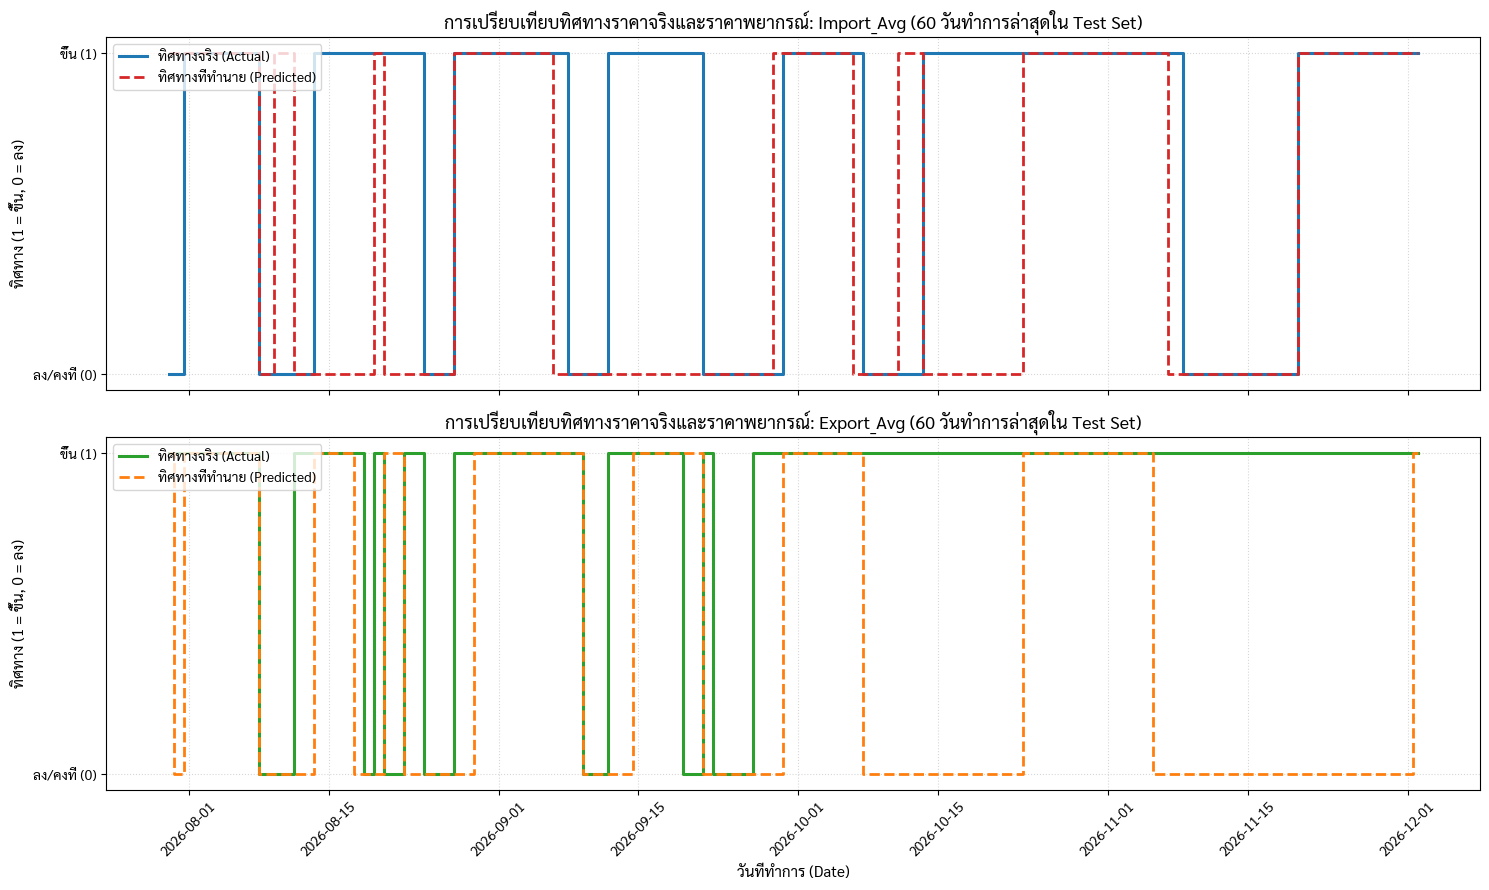

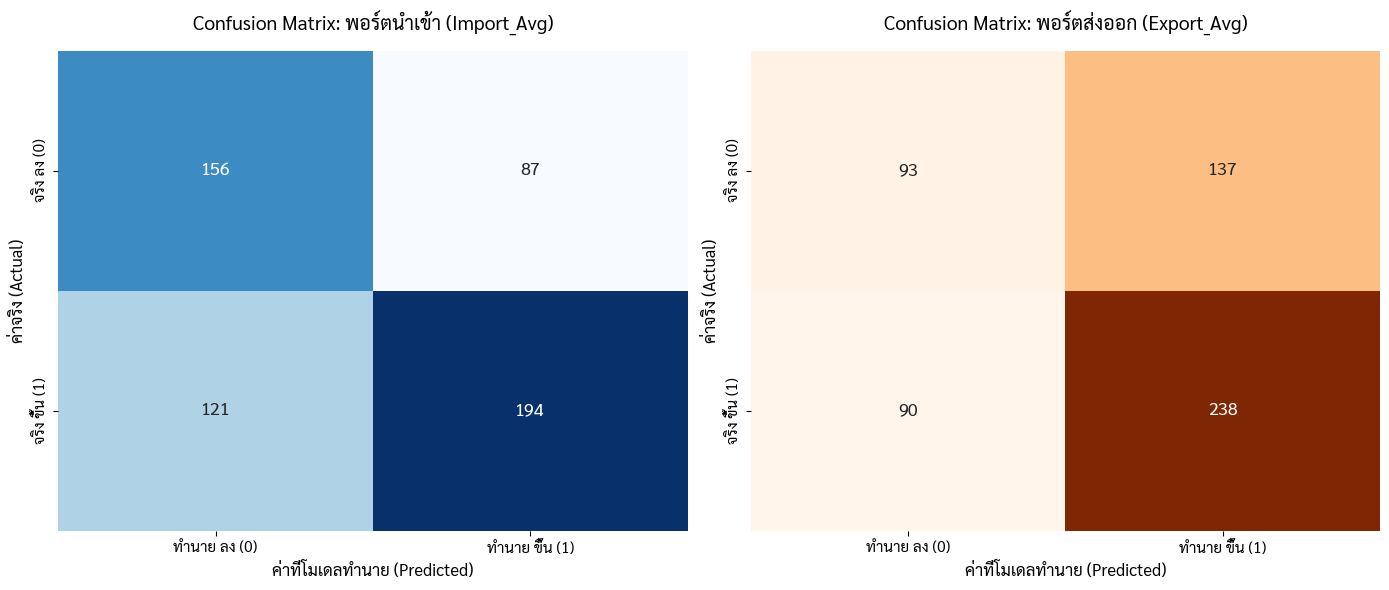

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. ตั้งค่าฟอนต์ภาษาไทยสำหรับการแสดงผลบนกราฟ
thai_font = configure_thai_font()

# 2. ดึงข้อมูลทำนายและค่าจริงบนชุด Test Set
y_test_import = df_test_predictions["Actual_Import"].values
y_test_export = df_test_predictions["Actual_Export"].values
preds_import = df_test_predictions["Pred_Import"].values
preds_export = df_test_predictions["Pred_Export"].values

# 3. เตรียมข้อมูลสำหรับพล็อตอนุกรมเวลาย้อนหลัง 60 วันทำการล่าสุด
plot_days = 60
df_time_plot = df_test_predictions.tail(plot_days).reset_index(drop=True)

# =========================================================================
# ส่วนที่ 1: กราฟเส้นเปรียบเทียบทิศทางจริง vs ทิศทางที่ทำนาย (60 วันล่าสุด)
# =========================================================================
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 9), sharex=True)

ax1.step(df_time_plot["Date"], df_time_plot["Actual_Import"], where="mid", label="ทิศทางจริง (Actual)", color="#1f77b4", linewidth=2.2)
ax1.step(df_time_plot["Date"], df_time_plot["Pred_Import"], where="mid", label="ทิศทางที่ทำนาย (Predicted)", color="#d62728", linestyle="--", linewidth=2.0)
ax1.set_title("การเปรียบเทียบทิศทางราคาจริงและราคาพยากรณ์: Import_Avg (60 วันทำการล่าสุดใน Test Set)", fontproperties=thai_font, fontsize=13, fontweight="bold")
ax1.set_ylabel("ทิศทาง (1 = ขึ้น, 0 = ลง)", fontproperties=thai_font, fontsize=11)
ax1.set_yticks([0, 1])
ax1.set_yticklabels(["ลง/คงที่ (0)", "ขึ้น (1)"], fontproperties=thai_font)
ax1.legend(prop=thai_font, loc="upper left")
ax1.grid(True, linestyle=":", alpha=0.5)

ax2.step(df_time_plot["Date"], df_time_plot["Actual_Export"], where="mid", label="ทิศทางจริง (Actual)", color="#2ca02c", linewidth=2.2)
ax2.step(df_time_plot["Date"], df_time_plot["Pred_Export"], where="mid", label="ทิศทางที่ทำนาย (Predicted)", color="#ff7f0e", linestyle="--", linewidth=2.0)
ax2.set_title("การเปรียบเทียบทิศทางราคาจริงและราคาพยากรณ์: Export_Avg (60 วันทำการล่าสุดใน Test Set)", fontproperties=thai_font, fontsize=13, fontweight="bold")
ax2.set_xlabel("วันที่ทำการ (Date)", fontproperties=thai_font, fontsize=11)
ax2.set_ylabel("ทิศทาง (1 = ขึ้น, 0 = ลง)", fontproperties=thai_font, fontsize=11)
ax2.set_yticks([0, 1])
ax2.set_yticklabels(["ลง/คงที่ (0)", "ขึ้น (1)"], fontproperties=thai_font)
ax2.legend(prop=thai_font, loc="upper left")
ax2.grid(True, linestyle=":", alpha=0.5)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# =========================================================================
# ส่วนที่ 2: แผนภาพ Confusion Matrix เคียงข้างกัน (ซ้าย-ขวา)
# =========================================================================
cm_import = confusion_matrix(y_test_import, preds_import)
cm_export = confusion_matrix(y_test_export, preds_export)

fig_cm, (ax_cm1, ax_cm2) = plt.subplots(1, 2, figsize=(14, 6))

sns.heatmap(
    cm_import, annot=True, fmt="d", cmap="Blues", ax=ax_cm1, cbar=False,
    xticklabels=["ทำนาย ลง (0)", "ทำนาย ขึ้น (1)"],
    yticklabels=["จริง ลง (0)", "จริง ขึ้น (1)"],
    annot_kws={"size": 13, "weight": "bold"},
)
ax_cm1.set_title("Confusion Matrix: พอร์ตนำเข้า (Import_Avg)", fontproperties=thai_font, fontsize=14, fontweight="bold", pad=15)
ax_cm1.set_xlabel("ค่าที่โมเดลทำนาย (Predicted)", fontproperties=thai_font, fontsize=12)
ax_cm1.set_ylabel("ค่าจริง (Actual)", fontproperties=thai_font, fontsize=12)
for label in ax_cm1.get_xticklabels() + ax_cm1.get_yticklabels():
    label.set_fontproperties(thai_font)
    label.set_fontsize(11)

sns.heatmap(
    cm_export, annot=True, fmt="d", cmap="Oranges", ax=ax_cm2, cbar=False,
    xticklabels=["ทำนาย ลง (0)", "ทำนาย ขึ้น (1)"],
    yticklabels=["จริง ลง (0)", "จริง ขึ้น (1)"],
    annot_kws={"size": 13, "weight": "bold"},
)
ax_cm2.set_title("Confusion Matrix: พอร์ตส่งออก (Export_Avg)", fontproperties=thai_font, fontsize=14, fontweight="bold", pad=15)
ax_cm2.set_xlabel("ค่าที่โมเดลทำนาย (Predicted)", fontproperties=thai_font, fontsize=12)
ax_cm2.set_ylabel("ค่าจริง (Actual)", fontproperties=thai_font, fontsize=12)
for label in ax_cm2.get_xticklabels() + ax_cm2.get_yticklabels():
    label.set_fontproperties(thai_font)
    label.set_fontsize(11)

plt.tight_layout()
plt.show()

### 4.6 การวิเคราะห์ระดับความน่าจะเป็นเชิงลึกและการปรับเกณฑ์ตัดสิน (Probability Distribution & Threshold Tuning Analysis)

จากข้อสังเกตบนกราฟทัศนภาพพยากรณ์ในช่วง 60 วันทำการล่าสุดของชุดข้อมูลทดสอบ (Test Set) ที่แสดงสัดส่วนการพยากรณ์ทิศทางเป็นบวก (Class 1) เป็นหลัก เซลล์นี้จะทำหน้าที่วิเคราะห์เชิงลึกโดย:
1. **วิเคราะห์สถิติเชิงบรรยาย (Descriptive Statistics):** ค่าต่ำสุด, ค่าเฉลี่ย, มัธยฐาน, ค่าสูงสุด และสัดส่วนที่เกิน `0.50` ของระดับความน่าจะเป็นบน Test Set และ 60 วันทำการล่าสุด
2. **แผนภาพวิเคราะห์การตัดสินใจพยากรณ์ (Probability Chart):** แสดงการสั่นไหวรายวันของความน่าจะเป็นเทียบกับเกณฑ์แบ่งแยกและทิศทางจริง
3. **ตารางเปรียบเทียบประสิทธิภาพการปรับเปลี่ยน Threshold (Sensitivity Analysis):** ทดสอบช่วง Threshold เพื่อประกอบการตัดสินใจเชิงกลยุทธ์สำหรับผู้บริหาร

=== [ตารางสรุปข้อมูลสถิติเชิงพรรณนาและการแจกแจงของค่าความน่าจะเป็น] ===


,ตัวแปรเป้าหมาย,ช่วงข้อมูล,Minimum,Median,Mean (ค่าเฉลี่ย),Maximum,สัดส่วนที่ทายเป็น 1 (> 0.50)
0,Import_Avg,ภาพรวม Test Set (558 วัน),0.0666,0.5041,0.5132,0.9344,50.36%
1,Import_Avg,60 วันทำการล่าสุด,0.1727,0.4931,0.5326,0.9344,48.33%
2,Export_Avg,ภาพรวม Test Set (558 วัน),0.2101,0.5457,0.5658,0.9654,67.20%
3,Export_Avg,60 วันทำการล่าสุด,0.2685,0.5163,0.5402,0.9547,53.33%


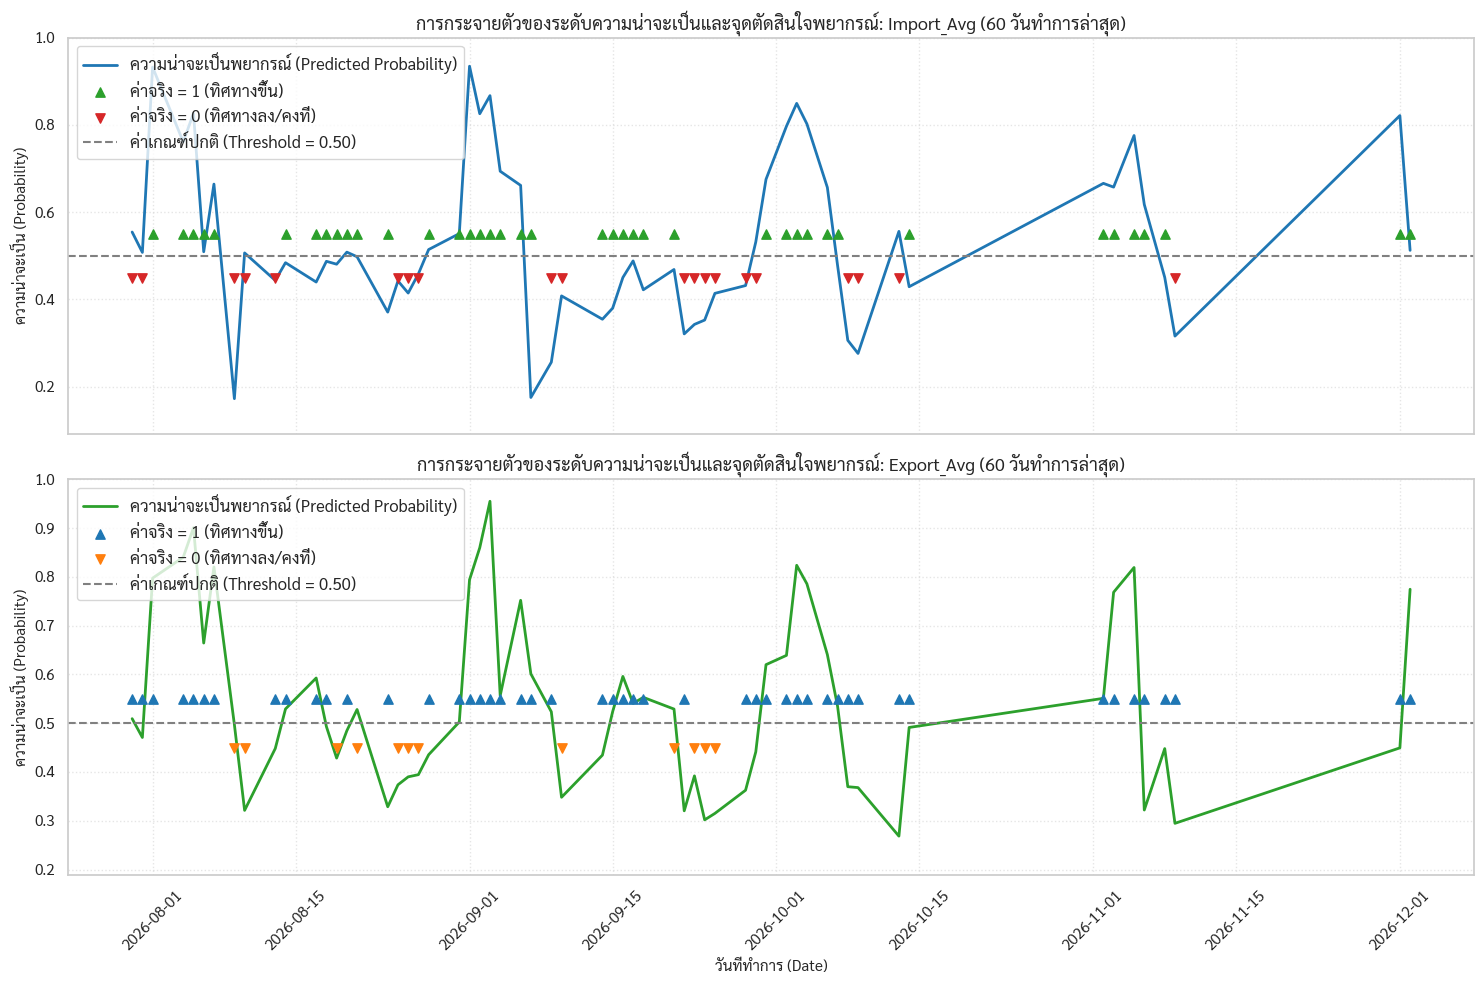


=== [ตารางวิเคราะห์การปรับเปลี่ยนค่าเกณฑ์ตัดสินใจพยากรณ์ (Threshold Sensitivity Analysis) บน Test Set] ===

* ตัวแปรเป้าหมาย: Import_Avg


,ตัวแปรเป้าหมาย,Threshold,Accuracy,Precision,Recall,F1-Score,สัดส่วนคำพยากรณ์คลาส 1
0,Import_Avg,0.50,0.627240,0.690391,0.615873,0.651007,50.36%
1,Import_Avg,0.52,0.621864,0.706349,0.565079,0.627866,45.16%
2,Import_Avg,0.55,0.621864,0.734234,0.517460,0.607076,39.78%
3,Import_Avg,0.58,0.600358,0.761364,0.425397,0.545825,31.54%
4,Import_Avg,0.60,0.596774,0.777778,0.400000,0.528302,29.03%



* ตัวแปรเป้าหมาย: Export_Avg


,ตัวแปรเป้าหมาย,Threshold,Accuracy,Precision,Recall,F1-Score,สัดส่วนคำพยากรณ์คลาส 1
0,Export_Avg,0.50,0.593190,0.634667,0.725610,0.677098,67.20%
1,Export_Avg,0.52,0.598566,0.655689,0.667683,0.661631,59.86%
2,Export_Avg,0.55,0.593190,0.687732,0.564024,0.619765,48.21%
3,Export_Avg,0.58,0.582437,0.711111,0.487805,0.578662,40.32%
4,Export_Avg,0.60,0.589606,0.751269,0.451220,0.563810,35.30%


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from IPython.display import display

# 1. ตั้งค่าธีมและฟอนต์ภาษาไทยสำหรับการพล็อตกราฟ
thai_font = configure_thai_font(style="whitegrid")

# 2. เตรียมโครงสร้าง DataFrame สำหรับการวิเคราะห์ระดับความน่าจะเป็น
df_prob_analysis = df_test_predictions[[
    "Date", "Actual_Import", "Prob_Import", "Actual_Export", "Prob_Export"
]].rename(columns={
    "Actual_Import": "True_Import",
    "Actual_Export": "True_Export",
}).copy()


# 3. จัดทำตารางสรุปสถิติเปรียบเทียบสัดส่วนและการแกว่งตัว
def get_stats_summary(df, label_prefix):
    summary_rows = []
    for c_name, target in [("Prob_Import", "Import_Avg"), ("Prob_Export", "Export_Avg")]:
        series_all = df[c_name]
        series_60 = df[c_name].tail(60)

        summary_rows.append({
            "ตัวแปรเป้าหมาย": target,
            "ช่วงข้อมูล": f"ภาพรวม {label_prefix}",
            "Minimum": f"{series_all.min():.4f}",
            "Median": f"{series_all.median():.4f}",
            "Mean (ค่าเฉลี่ย)": f"{series_all.mean():.4f}",
            "Maximum": f"{series_all.max():.4f}",
            "สัดส่วนที่ทายเป็น 1 (> 0.50)": f"{(series_all > 0.50).mean():.2%}",
        })
        summary_rows.append({
            "ตัวแปรเป้าหมาย": target,
            "ช่วงข้อมูล": "60 วันทำการล่าสุด",
            "Minimum": f"{series_60.min():.4f}",
            "Median": f"{series_60.median():.4f}",
            "Mean (ค่าเฉลี่ย)": f"{series_60.mean():.4f}",
            "Maximum": f"{series_60.max():.4f}",
            "สัดส่วนที่ทายเป็น 1 (> 0.50)": f"{(series_60 > 0.50).mean():.2%}",
        })
    return pd.DataFrame(summary_rows)


df_stats_summary = get_stats_summary(df_prob_analysis, f"Test Set ({len(df_prob_analysis)} วัน)")
print("=== [ตารางสรุปข้อมูลสถิติเชิงพรรณนาและการแจกแจงของค่าความน่าจะเป็น] ===")
display(df_stats_summary)

# =========================================================================
# ส่วนที่ 1: พล็อตกราฟค่าความน่าจะเป็นเทียบกับเส้นเกณฑ์ 0.50 (60 วันล่าสุด)
# =========================================================================
df_last_60 = df_prob_analysis.tail(60).reset_index(drop=True)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 10), sharex=True)

# กราฟย่อยที่ 1: Import_Avg
imp_ymin = max(0.0, min(df_last_60["Prob_Import"].min(), 0.45) - 0.08)
imp_ymax = min(1.0, max(df_last_60["Prob_Import"].max(), 0.55) + 0.08)
ax1.plot(df_last_60["Date"], df_last_60["Prob_Import"], color="#1f77b4", label="ความน่าจะเป็นพยากรณ์ (Predicted Probability)", linewidth=2)
ax1.scatter(df_last_60[df_last_60["True_Import"] == 1]["Date"], [0.55] * int((df_last_60["True_Import"] == 1).sum()), color="#2ca02c", marker="^", s=45, label="ค่าจริง = 1 (ทิศทางขึ้น)", zorder=5)
ax1.scatter(df_last_60[df_last_60["True_Import"] == 0]["Date"], [0.45] * int((df_last_60["True_Import"] == 0).sum()), color="#d62728", marker="v", s=45, label="ค่าจริง = 0 (ทิศทางลง/คงที่)", zorder=5)
ax1.axhline(0.50, color="grey", linestyle="--", linewidth=1.5, label="ค่าเกณฑ์ปกติ (Threshold = 0.50)")
ax1.set_title("การกระจายตัวของระดับความน่าจะเป็นและจุดตัดสินใจพยากรณ์: Import_Avg (60 วันทำการล่าสุด)", fontproperties=thai_font, fontsize=13, fontweight="bold")
ax1.set_ylabel("ความน่าจะเป็น (Probability)", fontproperties=thai_font, fontsize=11)
ax1.set_ylim(imp_ymin, imp_ymax)
ax1.legend(prop=thai_font, loc="upper left")
ax1.grid(True, linestyle=":", alpha=0.5)

# กราฟย่อยที่ 2: Export_Avg
exp_ymin = max(0.0, min(df_last_60["Prob_Export"].min(), 0.45) - 0.08)
exp_ymax = min(1.0, max(df_last_60["Prob_Export"].max(), 0.55) + 0.08)
ax2.plot(df_last_60["Date"], df_last_60["Prob_Export"], color="#2ca02c", label="ความน่าจะเป็นพยากรณ์ (Predicted Probability)", linewidth=2)
ax2.scatter(df_last_60[df_last_60["True_Export"] == 1]["Date"], [0.55] * int((df_last_60["True_Export"] == 1).sum()), color="#1f77b4", marker="^", s=45, label="ค่าจริง = 1 (ทิศทางขึ้น)", zorder=5)
ax2.scatter(df_last_60[df_last_60["True_Export"] == 0]["Date"], [0.45] * int((df_last_60["True_Export"] == 0).sum()), color="#ff7f0e", marker="v", s=45, label="ค่าจริง = 0 (ทิศทางลง/คงที่)", zorder=5)
ax2.axhline(0.50, color="grey", linestyle="--", linewidth=1.5, label="ค่าเกณฑ์ปกติ (Threshold = 0.50)")
ax2.set_title("การกระจายตัวของระดับความน่าจะเป็นและจุดตัดสินใจพยากรณ์: Export_Avg (60 วันทำการล่าสุด)", fontproperties=thai_font, fontsize=13, fontweight="bold")
ax2.set_xlabel("วันที่ทำการ (Date)", fontproperties=thai_font, fontsize=11)
ax2.set_ylabel("ความน่าจะเป็น (Probability)", fontproperties=thai_font, fontsize=11)
ax2.set_ylim(exp_ymin, exp_ymax)
ax2.legend(prop=thai_font, loc="upper left")
ax2.grid(True, linestyle=":", alpha=0.5)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# =========================================================================
# ส่วนที่ 2: การทดสอบเปรียบเทียบค่าเกณฑ์พยากรณ์ (Threshold Sensitivity Analysis)
# =========================================================================
thresholds = [0.50, 0.52, 0.55, 0.58, 0.60]
threshold_tuning_results = []

y_true_import = df_prob_analysis["True_Import"].values
probs_import = df_prob_analysis["Prob_Import"].values
y_true_export = df_prob_analysis["True_Export"].values
probs_export = df_prob_analysis["Prob_Export"].values

for target_name, true_vals, prob_vals in [("Import_Avg", y_true_import, probs_import), ("Export_Avg", y_true_export, probs_export)]:
    for th in thresholds:
        tuned_preds = np.where(prob_vals > th, 1, 0)
        threshold_tuning_results.append({
            "ตัวแปรเป้าหมาย": target_name,
            "Threshold": f"{th:.2f}",
            "Accuracy": accuracy_score(true_vals, tuned_preds),
            "Precision": precision_score(true_vals, tuned_preds, zero_division=0),
            "Recall": recall_score(true_vals, tuned_preds, zero_division=0),
            "F1-Score": f1_score(true_vals, tuned_preds, zero_division=0),
            "สัดส่วนคำพยากรณ์คลาส 1": f"{np.mean(tuned_preds == 1):.2%}",
        })

df_tuning_summary = pd.DataFrame(threshold_tuning_results)
print("\n=== [ตารางวิเคราะห์การปรับเปลี่ยนค่าเกณฑ์ตัดสินใจพยากรณ์ (Threshold Sensitivity Analysis) บน Test Set] ===")
for target in ["Import_Avg", "Export_Avg"]:
    print(f"\n* ตัวแปรเป้าหมาย: {target}")
    display(df_tuning_summary[df_tuning_summary["ตัวแปรเป้าหมาย"] == target].reset_index(drop=True))

### 4.7 การวิเคราะห์ประสิทธิภาพและการแจกแจงความน่าจะเป็นแบบรายปี (Yearly Performance & Probability Breakdown on Test Set)

เพื่อทำความเข้าใจการเปลี่ยนแปลงในเชิงพฤติกรรมความแม่นยำ (Model Robustness & Temporal Drift) ของตัวแบบที่ดีที่สุดสำหรับ `Import_Avg` และ `Export_Avg` เซลล์นี้จะทำหน้าที่แบ่งหน้าต่างข้อมูลการประเมินออกเป็นรายปีตามปฏิทินจริงในชุด Test Set (2024, 2025, 2026) โดย:
1. วิเคราะห์สัดส่วนคลาสจริงเทียบกับสัดส่วนพยากรณ์รายปี
2. สรุปมาตรวัดชี้วัดประสิทธิภาพ (ROC-AUC, Accuracy, Precision, Recall, F1-Score และค่ากลาง Probabilities) รายปี
3. แสดงแผนภูมิแท่งเปรียบเทียบประสิทธิผลรายปี

=== [ตารางวิเคราะห์สรุปผลประสิทธิภาพและการแจกแจงแบบรายปีบน Test Set] ===

* ตัวแปรเป้าหมาย: Import_Avg


,ตัวแปรเป้าหมาย,ปี ค.ศ.,จำนวนแถว (วัน),สัดส่วนคลาสจริง 1 (Actual Up),สัดส่วนพยากรณ์ 1 (Pred Up),ROC-AUC,Accuracy,Precision,Recall,F1-Score,Mean Prob,Median Prob
0,Import_Avg,2024,97,54.64%,34.02%,0.5587,0.5258,0.6061,0.3774,0.4651,0.4973,0.4681
1,Import_Avg,2025,261,52.49%,57.09%,0.6924,0.6475,0.6510,0.7080,0.6783,0.5247,0.5279
2,Import_Avg,2026,200,62.50%,49.50%,0.7475,0.6500,0.7778,0.6160,0.6875,0.5059,0.4989



* ตัวแปรเป้าหมาย: Export_Avg


,ตัวแปรเป้าหมาย,ปี ค.ศ.,จำนวนแถว (วัน),สัดส่วนคลาสจริง 1 (Actual Up),สัดส่วนพยากรณ์ 1 (Pred Up),ROC-AUC,Accuracy,Precision,Recall,F1-Score,Mean Prob,Median Prob
0,Export_Avg,2024,97,48.45%,59.79%,0.6647,0.5773,0.5517,0.6809,0.6095,0.5349,0.5153
1,Export_Avg,2025,261,53.64%,81.99%,0.6380,0.5785,0.5701,0.8714,0.6893,0.6049,0.5809
2,Export_Avg,2026,200,70.50%,51.50%,0.6992,0.6200,0.8155,0.5957,0.6885,0.5299,0.5077


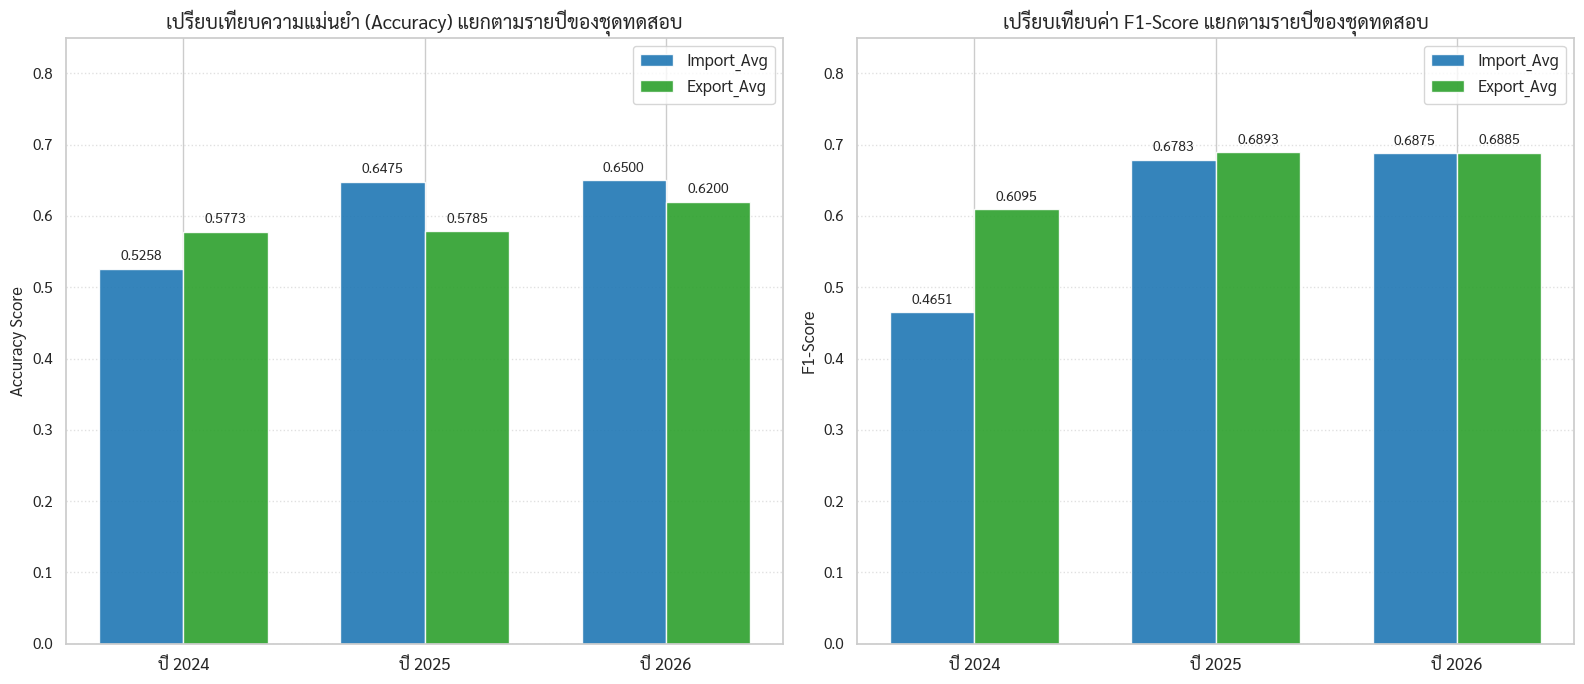

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, accuracy_score, precision_score, recall_score, f1_score
from IPython.display import display

# 1. ตั้งค่าธีมและฟอนต์ภาษาไทยสำหรับ Matplotlib และ Seaborn
thai_font = configure_thai_font(style="whitegrid")

# 2. เตรียมข้อมูลรายปีจาก df_test_predictions
df_yearly_base = df_test_predictions.rename(columns={
    "Actual_Import": "True_Import",
    "Actual_Export": "True_Export",
}).copy()
df_yearly_base["Year"] = pd.to_datetime(df_yearly_base["Date"]).dt.year

unique_years = sorted(df_yearly_base["Year"].unique())

# 3. คำนวณสถิติและประสิทธิภาพรายปีแยกตามแต่ละ Target
yearly_metrics_rows = []
for target, true_col, pred_col, prob_col in [
    ("Import_Avg", "True_Import", "Pred_Import", "Prob_Import"),
    ("Export_Avg", "True_Export", "Pred_Export", "Prob_Export"),
]:
    for year in unique_years:
        df_sub = df_yearly_base[df_yearly_base["Year"] == year]
        if df_sub.empty:
            continue

        y_true = df_sub[true_col].values
        y_pred = df_sub[pred_col].values
        y_prob = df_sub[prob_col].values

        auc = roc_auc_score(y_true, y_prob) if len(np.unique(y_true)) > 1 else 0.50

        yearly_metrics_rows.append({
            "ตัวแปรเป้าหมาย": target,
            "ปี ค.ศ.": year,
            "จำนวนแถว (วัน)": len(df_sub),
            "สัดส่วนคลาสจริง 1 (Actual Up)": f"{np.mean(y_true == 1):.2%}",
            "สัดส่วนพยากรณ์ 1 (Pred Up)": f"{np.mean(y_pred == 1):.2%}",
            "ROC-AUC": round(auc, 4),
            "Accuracy": round(accuracy_score(y_true, y_pred), 4),
            "Precision": round(precision_score(y_true, y_pred, zero_division=0), 4),
            "Recall": round(recall_score(y_true, y_pred, zero_division=0), 4),
            "F1-Score": round(f1_score(y_true, y_pred, zero_division=0), 4),
            "Mean Prob": round(float(np.mean(y_prob)), 4),
            "Median Prob": round(float(np.median(y_prob)), 4),
        })

df_yearly_summary = pd.DataFrame(yearly_metrics_rows)

print("=== [ตารางวิเคราะห์สรุปผลประสิทธิภาพและการแจกแจงแบบรายปีบน Test Set] ===")
for target in ["Import_Avg", "Export_Avg"]:
    print(f"\n* ตัวแปรเป้าหมาย: {target}")
    display(df_yearly_summary[df_yearly_summary["ตัวแปรเป้าหมาย"] == target].reset_index(drop=True))

# =========================================================================
# 4. พล็อตกราฟเปรียบเทียบผลประสิทธิภาพรายปี (Accuracy & F1-Score)
# =========================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

x = np.arange(len(unique_years))
width = 0.35

import_accs = df_yearly_summary[df_yearly_summary["ตัวแปรเป้าหมาย"] == "Import_Avg"]["Accuracy"].values
export_accs = df_yearly_summary[df_yearly_summary["ตัวแปรเป้าหมาย"] == "Export_Avg"]["Accuracy"].values
acc_ylim = min(1.05, max(0.85, float(max(import_accs.max(), export_accs.max())) + 0.12))

rects1 = ax1.bar(x - width / 2, import_accs, width, label="Import_Avg", color="#1f77b4", alpha=0.9)
rects2 = ax1.bar(x + width / 2, export_accs, width, label="Export_Avg", color="#2ca02c", alpha=0.9)
ax1.set_title("เปรียบเทียบความแม่นยำ (Accuracy) แยกตามรายปีของชุดทดสอบ", fontproperties=thai_font, fontsize=14, fontweight="bold")
ax1.set_xticks(x)
ax1.set_xticklabels([f"ปี {yr}" for yr in unique_years], fontproperties=thai_font, fontsize=12)
ax1.set_ylabel("Accuracy Score", fontproperties=thai_font, fontsize=12)
ax1.set_ylim(0.0, acc_ylim)
ax1.legend(prop=thai_font)
ax1.grid(axis="y", linestyle=":", alpha=0.6)

import_f1s = df_yearly_summary[df_yearly_summary["ตัวแปรเป้าหมาย"] == "Import_Avg"]["F1-Score"].values
export_f1s = df_yearly_summary[df_yearly_summary["ตัวแปรเป้าหมาย"] == "Export_Avg"]["F1-Score"].values
f1_ylim = min(1.05, max(0.85, float(max(import_f1s.max(), export_f1s.max())) + 0.12))

rects3 = ax2.bar(x - width / 2, import_f1s, width, label="Import_Avg", color="#1f77b4", alpha=0.9)
rects4 = ax2.bar(x + width / 2, export_f1s, width, label="Export_Avg", color="#2ca02c", alpha=0.9)
ax2.set_title("เปรียบเทียบค่า F1-Score แยกตามรายปีของชุดทดสอบ", fontproperties=thai_font, fontsize=14, fontweight="bold")
ax2.set_xticks(x)
ax2.set_xticklabels([f"ปี {yr}" for yr in unique_years], fontproperties=thai_font, fontsize=12)
ax2.set_ylabel("F1-Score", fontproperties=thai_font, fontsize=12)
ax2.set_ylim(0.0, f1_ylim)
ax2.legend(prop=thai_font)
ax2.grid(axis="y", linestyle=":", alpha=0.6)


def set_bar_labels(rects, ax):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(
            f"{height:.4f}",
            xy=(rect.get_x() + rect.get_width() / 2, height),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="semibold",
        )


set_bar_labels(rects1, ax1)
set_bar_labels(rects2, ax1)
set_bar_labels(rects3, ax2)
set_bar_labels(rects4, ax2)

plt.tight_layout()
plt.show()

### 4.8 การกระจายตัวของระดับความน่าจะเป็นตลอดช่วงชุดทดสอบ (Full Test-Set Probability Trajectory)

แสดงแนวโน้มค่าความน่าจะเป็นพยากรณ์รายวันตลอดทุกวันทำการในชุดข้อมูลทดสอบ (Test Set) เทียบกับจุดสังเกตทิศทางราคาจริง (`1 = ขึ้น`, `0 = ลง/คงที่`) และเส้นเกณฑ์ปกติ `0.50` เพื่อตรวจดูเสถียรภาพของการพยากรณ์ในระยะยาว

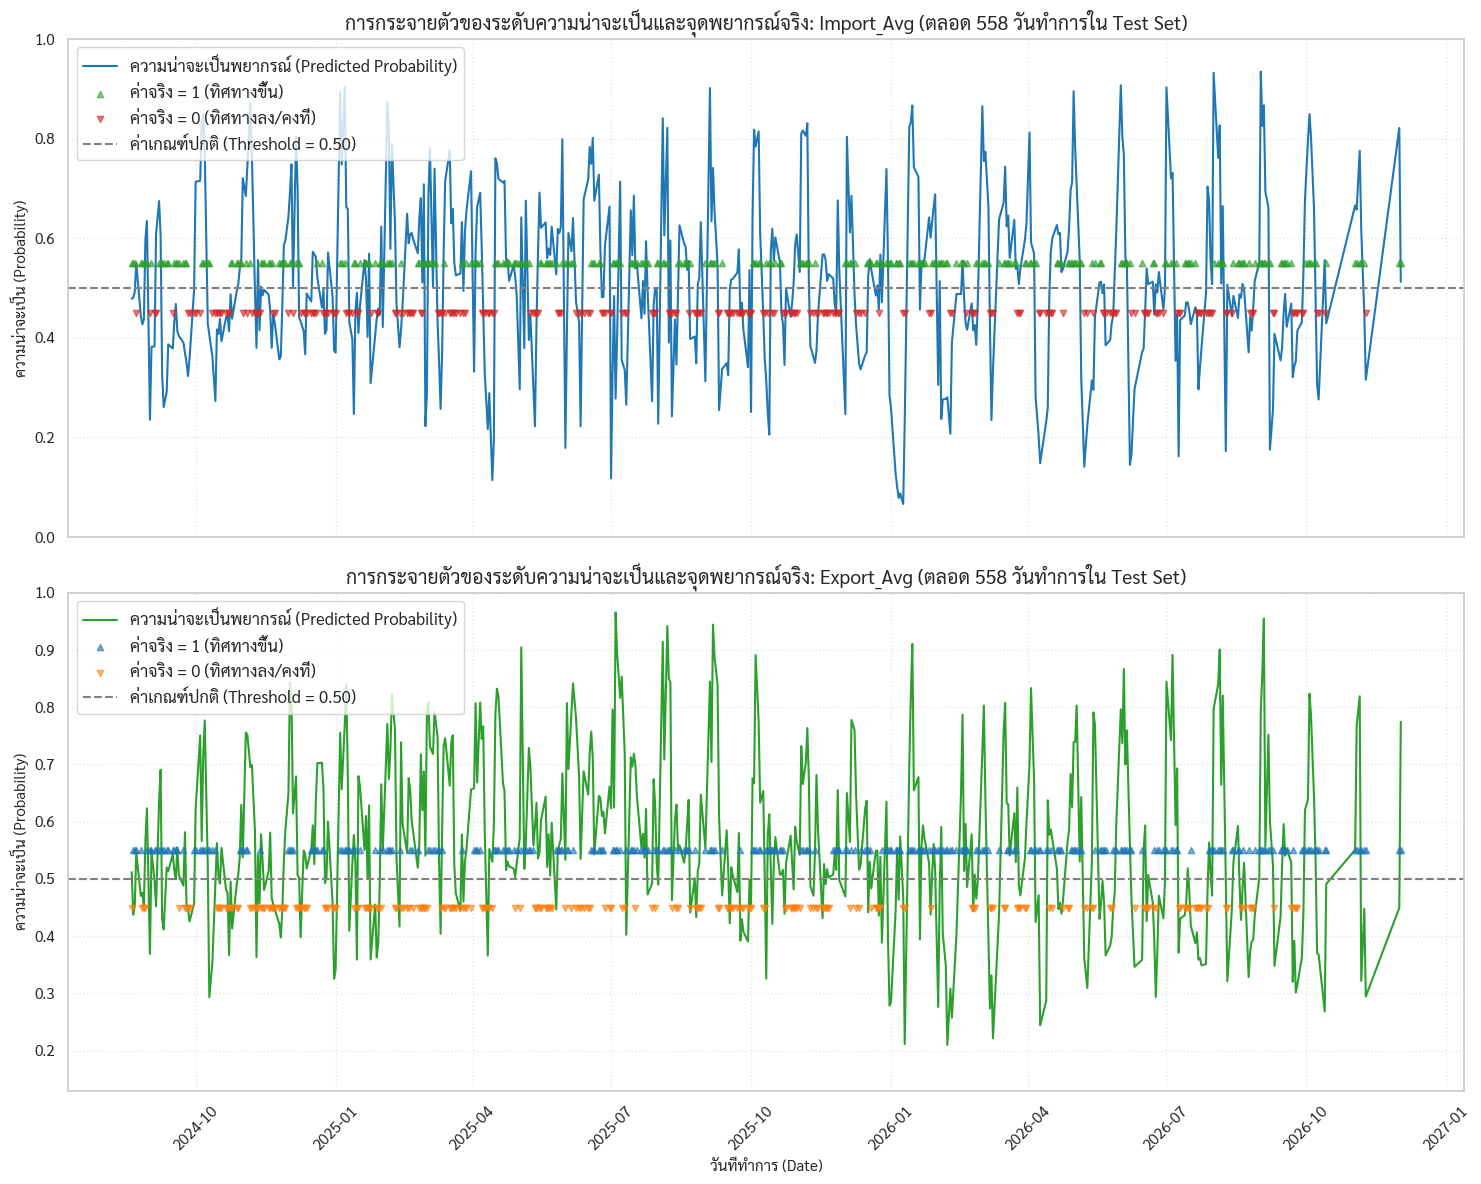

In [7]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. ตั้งค่าธีมและฟอนต์ภาษาไทยสำหรับการพล็อตกราฟ
thai_font = configure_thai_font(style="whitegrid")

# 2. ดึงข้อมูล Test Set ทั้งหมดจาก df_test_predictions
df_plot_full = df_test_predictions.copy()
df_plot_full["Date"] = pd.to_datetime(df_plot_full["Date"])
n_test_days = len(df_plot_full)

# 3. พล็อตกราฟเปรียบเทียบระดับความน่าจะเป็นรายวันตลอด Test Set
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 12), sharex=True)

# Subplot 1: Import_Avg
imp_ymin = max(0.0, min(df_plot_full["Prob_Import"].min(), 0.45) - 0.08)
imp_ymax = min(1.0, max(df_plot_full["Prob_Import"].max(), 0.55) + 0.08)
ax1.plot(df_plot_full["Date"], df_plot_full["Prob_Import"], color="#1f77b4", label="ความน่าจะเป็นพยากรณ์ (Predicted Probability)", linewidth=1.5)
ax1.scatter(df_plot_full[df_plot_full["Actual_Import"] == 1]["Date"], [0.55] * int((df_plot_full["Actual_Import"] == 1).sum()), color="#2ca02c", marker="^", s=20, alpha=0.6, label="ค่าจริง = 1 (ทิศทางขึ้น)", zorder=5)
ax1.scatter(df_plot_full[df_plot_full["Actual_Import"] == 0]["Date"], [0.45] * int((df_plot_full["Actual_Import"] == 0).sum()), color="#d62728", marker="v", s=20, alpha=0.6, label="ค่าจริง = 0 (ทิศทางลง/คงที่)", zorder=5)
ax1.axhline(0.50, color="grey", linestyle="--", linewidth=1.5, label="ค่าเกณฑ์ปกติ (Threshold = 0.50)")
ax1.set_title(f"การกระจายตัวของระดับความน่าจะเป็นและจุดพยากรณ์จริง: Import_Avg (ตลอด {n_test_days} วันทำการใน Test Set)", fontproperties=thai_font, fontsize=14, fontweight="bold")
ax1.set_ylabel("ความน่าจะเป็น (Probability)", fontproperties=thai_font, fontsize=11)
ax1.set_ylim(imp_ymin, imp_ymax)
ax1.legend(prop=thai_font, loc="upper left")
ax1.grid(True, linestyle=":", alpha=0.5)

# Subplot 2: Export_Avg
exp_ymin = max(0.0, min(df_plot_full["Prob_Export"].min(), 0.45) - 0.08)
exp_ymax = min(1.0, max(df_plot_full["Prob_Export"].max(), 0.55) + 0.08)
ax2.plot(df_plot_full["Date"], df_plot_full["Prob_Export"], color="#2ca02c", label="ความน่าจะเป็นพยากรณ์ (Predicted Probability)", linewidth=1.5)
ax2.scatter(df_plot_full[df_plot_full["Actual_Export"] == 1]["Date"], [0.55] * int((df_plot_full["Actual_Export"] == 1).sum()), color="#1f77b4", marker="^", s=20, alpha=0.6, label="ค่าจริง = 1 (ทิศทางขึ้น)", zorder=5)
ax2.scatter(df_plot_full[df_plot_full["Actual_Export"] == 0]["Date"], [0.45] * int((df_plot_full["Actual_Export"] == 0).sum()), color="#ff7f0e", marker="v", s=20, alpha=0.6, label="ค่าจริง = 0 (ทิศทางลง/คงที่)", zorder=5)
ax2.axhline(0.50, color="grey", linestyle="--", linewidth=1.5, label="ค่าเกณฑ์ปกติ (Threshold = 0.50)")
ax2.set_title(f"การกระจายตัวของระดับความน่าจะเป็นและจุดพยากรณ์จริง: Export_Avg (ตลอด {n_test_days} วันทำการใน Test Set)", fontproperties=thai_font, fontsize=14, fontweight="bold")
ax2.set_xlabel("วันที่ทำการ (Date)", fontproperties=thai_font, fontsize=11)
ax2.set_ylabel("ความน่าจะเป็น (Probability)", fontproperties=thai_font, fontsize=11)
ax2.set_ylim(exp_ymin, exp_ymax)
ax2.legend(prop=thai_font, loc="upper left")
ax2.grid(True, linestyle=":", alpha=0.5)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()